# 07a — Study B: Adding Steering Winds (features and XGBoost)

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric sections:** Data Sources (second dataset), EDA of the second dataset, Feature Engineering, Model Training, Model Evaluation

So far, every model in this project has seen only the storm's own track: where it has been, how fast it was
moving, how strong it was. After two rounds of tuning, those models have settled at about **144 km** of
mean 24-hour error on the validation seasons, while the National Hurricane Center's official forecasts reach
about 63 km in the Atlantic. Tuning alone isn't going to close a gap like that.

What the official forecasts have, and our models don't, is the **atmosphere around the storm**. A tropical
cyclone is carried along by the large-scale winds it sits in, the *steering flow*, much like a leaf on a
river (Chan, 2005). Persistence assumes the river keeps flowing the same way; the steering winds show where
it's actually flowing right now. So here, we bring in a second dataset: the **NCEP/NCAR Reanalysis 1**
(Kalnay et al., 1996), a consistent, gridded record of the global atmosphere every 6 hours since 1948.

Together, this notebook and the next one form **Study B**, a self-contained experiment that asks one question:

> *Holding everything else fixed, how much do steering winds improve a 24-hour track forecast?*

| | |
|---|---|
| **Inputs** | `data/processed/tracks_clean.csv.gz`; NCEP winds in `data/raw/ncep/` (from `scripts/download_ncep.py`) |
| **Shared code** | `src/stormtrack/steering.py`: computes the steering features |
| **Outputs** | `data/processed/steering_features.csv.gz`, `preds_studyb_xgb.csv`, figures `fig23`–`fig26` (with `fig23b`–`fig23e` for the EDA) |

XGBoost runs here, and the GRU in notebook 07b. They live in separate notebooks for the same reason as
before: on macOS, XGBoost and PyTorch can't safely share one Python session.

### Setting things up

Alongside the usual libraries and project code, here we import `steering.py`, the new module that turns raw
wind grids into features. As in notebook 03, XGBoost is capped at 4 CPU threads and every seed is fixed.

In [1]:
# Imports and paths
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_clean, PROCESSED
from stormtrack.geo import haversine_km
from stormtrack.windows import (build_samples, persistence_displacement, track_error_km,
                                FEATURE_COLS, TARGET_COLS, MOTION_COLS)
from stormtrack.steering import (steering_features, available_years, NCEP_DIR, LEVELS, RING_KM,
                                 STEERING_COLS, RING_COLS, KM_PER_24H)

FIG_DIR, MODEL_DIR = ROOT / "reports" / "figures", ROOT / "models"
SEED, N_THREADS = 42, 4
XGB_CFG = json.loads((MODEL_DIR / "xgb_config.json").read_text())     # settings chosen in notebook 03

pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}")

## 1. The second dataset

Before using the winds, it's worth seeing exactly what was downloaded. The script `scripts/download_ncep.py`
pulled the eastward (`u`) and northward (`v`) wind at three heights: 850 hPa (about 1.5 km up), 500 hPa
(about 5.5 km) and 200 hPa (about 12 km). Together they span the depth of the atmosphere that steers a
tropical cyclone. The grid spacing is 2.5°, every 6 hours, matching the 00/06/12/18 UTC timing of the
IBTrACS fixes exactly.

NOAA's server began refusing requests partway through the download, so not every year arrived. In the
cell below, we list what's on disk and open one year to check its layout.

In [2]:
# So, first, which years of NCEP winds made it to disk, and which are missing after the rate-limited download?
years = sorted(available_years())
missing = sorted(set(range(1980, 2025)) - set(years))
print(f"Wind years on disk: {len(years)} ({years[0]}-{years[-1]}), missing: {missing}")

# Then we open one year to see its layout: time x level x latitude x longitude, with u and v wind.
with xr.open_dataset(NCEP_DIR / f"ncep_winds_{years[0]}.nc") as ds:
    print(ds)
    print(f"\nTime steps: {ds.sizes['time']}, first {str(ds.time.values[0])[:16]}, last {str(ds.time.values[-1])[:16]}")

Wind years on disk: 31 (1980-2012), missing: [2001, 2009, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


<xarray.Dataset> Size: 506MB
Dimensions:  (time: 1464, level: 3, lat: 50, lon: 144)
Coordinates:
  * time     (time) datetime64[ns] 12kB 1980-01-01 ... 1980-12-31T18:00:00
  * level    (level) float32 12B 850.0 500.0 200.0
  * lat      (lat) float32 200B 62.5 60.0 57.5 55.0 ... -52.5 -55.0 -57.5 -60.0
  * lon      (lon) float32 576B 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
Data variables:
    uwnd     (time, level, lat, lon) float64 253MB ...
    vwnd     (time, level, lat, lon) float64 253MB ...
Attributes:
    source:   NCEP/NCAR Reanalysis 1, NOAA PSL (Kalnay et al., 1996)
    subset:   levels [850, 500, 200] hPa, lat 62.5 to -60.0, 6-hourly

Time steps: 1464, first 1980-01-01T00:00, last 1980-12-31T18:00


So, 31 of the 45 years made it: 1980 through 2012, minus 2001 and 2009. Each year's file holds 1,464 time steps (every 6 hours), 3 heights, and a 50 × 144 grid covering 62.5°N to 60°S around the whole globe, which comfortably contains every storm in the project. On disk the winds are packed to 0.01 m/s, and they're unpacked to ordinary numbers when read, as the printout shows.

## 2. A new split for Study B

Since the winds only cover part of the track record, Study B gets its own train / validation / test split,
built from the forecasts whose origin falls in a year with wind data. Just like the main split, it is
**chronological** and assigns whole storm seasons, so a model is always trained on the past and judged on
the future, and no storm is ever split across two sets:

| Study B split | Seasons |
|---|---|
| Train | 1980–2004 |
| Validation | 2005–2008 |
| Test | 2009–2013 |

Here, the seasons inside the original training period get reused as validation and test data. That's fine
because Study B trains every model from scratch on its own split. What it does mean is that Study B's errors
can't be compared directly with the main study's 2017–2019 numbers, only with each other.

In [3]:
# Here, we rebuild the 24-h forecast samples from the clean tracks, exactly as in notebooks 03-06.
tracks = load_clean()
S_all = build_samples(tracks)
# Next, we keep the forecasts whose origin falls in a year with wind data (seasons up to 2013), and split
# them in time order by whole seasons: train up to 2004, validation 2005-2008, test 2009-2013.
S = S_all[S_all["ISO_TIME"].dt.year.isin(years) & S_all["SEASON"].le(2013)].reset_index(drop=True)
S["split_b"] = np.select([S["SEASON"].le(2004), S["SEASON"].le(2008)], ["train", "val"], "test")

# And here is how big each Study B split turns out to be.
split_tab = (S.groupby("split_b").agg(samples=("SID", "size"), storms=("SID", "nunique"),
                                      first_season=("SEASON", "min"), last_season=("SEASON", "max"))
               .reindex(["train", "val", "test"]))
print(f"Study B uses {len(S):,} of the {len(S_all):,} forecast samples ({100 * len(S) / len(S_all):.0f}%)")
split_tab

Study B uses 56,434 of the 76,613 forecast samples (74%)


,samples,storms,first_season,last_season
split_b,,,,
train,46896,2194,1980,2004
val,5514,343,2005,2008
test,4024,241,2009,2013


Here, Study B keeps **56,434** forecasts, about three quarters of the full set, and still has plenty of data at every stage: 46,896 training forecasts from 2,194 storms, 5,514 for validation and 4,024 for testing. Since 2009 and 2013 have no wind files, the test set is drawn mostly from the 2010–2012 seasons, plus Southern Hemisphere storms that formed late in 2008 and 2012 (their seasons are counted as 2009 and 2013). At 241 storms, it's about the same size as the main study's validation set.

## 3. Measuring the steering flow

Now for the feature engineering. For every forecast, `steering_features()` looks at the wind in a ring
**200 to 800 km** from the storm's centre at the forecast time. The inner edge skips the storm's own
swirling winds, which would otherwise swamp the average, and the outer edge keeps the average local. Grid
points in the ring are averaged at each of the three heights, weighted by the area they cover. This ring
average is a standard way of estimating the steering flow (Chan & Gray, 1982).

From those six numbers, the function also derives:

| Feature | Meaning |
|---|---|
| `dlm_u`, `dlm_v` | **Deep-layer mean** wind: the average of the three heights, the classic single measure of steering |
| `shear_u`, `shear_v` | Upper minus lower wind (**vertical shear**), which tilts storms and makes them drift |
| `steer_dx`, `steer_dy` | How far the deep-layer wind would carry the storm in 24 hours, in km |
| `steer_minus_persist_dx/dy` | How far that steering forecast is from persistence: where the river is bending |

Only the wind at the forecast time is used, never anything later, so a real forecaster would have all of
this in hand. The last pair is there for a reason: since the models predict a *correction to persistence*,
the most useful thing to tell them is where the steering flow disagrees with persistence.

In the cell below, we compute everything for all Study B forecasts (about half a minute).

In [4]:
# Now the steering features for every forecast: winds averaged over a ring 200-800 km from the center
# at the forecast time only (no future data), plus the deep-layer mean, shear and steering-vs-persistence.
t0 = time.time()
F = steering_features(S)
S = pd.concat([S, F], axis=1)
print(f"Steering features for {len(S):,} forecasts in {time.time() - t0:.0f} s; "
      f"missing values: {int(F.isna().sum().sum())}")
# As a quick range check, we summarize every new feature (m/s for winds, km for displacements).
S[STEERING_COLS].describe().T[["mean", "std", "min", "max"]].round(1)

Steering features for 56,434 forecasts in 24 s; missing values: 0


,mean,std,min,max
u850,-1.3,3.4,-14.8,18.1
v850,0.6,2.9,-14.8,14.8
u500,-1.0,4.1,-16.6,23.7
v500,0.6,3.0,-14.0,14.2
u200,-0.4,7.1,-24.2,45.8
v200,-0.3,4.9,-25.1,25.4
dlm_u,-0.9,3.9,-13.7,25.6
dlm_v,0.3,2.9,-15.1,14.9
shear_u,1.0,7.6,-29.2,38.7
shear_v,-0.9,5.0,-23.3,23.3


Every forecast got its features, with no gaps. A few values are a good sanity check on the physics:

- On average the deep-layer flow blows slightly toward the west (`dlm_u` of −0.9 m/s), as expected in the tropics, where most of these forecasts sit inside the easterly trade winds.
- At 200 hPa the wind reaches 46 m/s, the subtropical jet stream that sweeps storms away once they recurve to higher latitudes.
- `steer_minus_persist_dx` averages **+99 km**, so storms tend to travel further west than the steering wind alone would carry them. That's the well-known **beta drift**: a cyclone's own circulation interacts with the Earth's rotation and pushes it poleward and westward, relative to the surrounding flow (Chan, 2005). The models will need to learn that offset.

To make the idea concrete, Figure 23 draws the steering flow around one storm. We picked Hurricane Katrina
on the morning of 28 August 2005, shortly before landfall in Louisiana. Arrows show the deep-layer wind,
the two circles mark the 200–800 km ring, and the coloured arrows compare the 24-hour forecasts from
persistence and from the steering wind alone with where Katrina actually went.

saved reports/figures/fig23_steering_ring_katrina.png


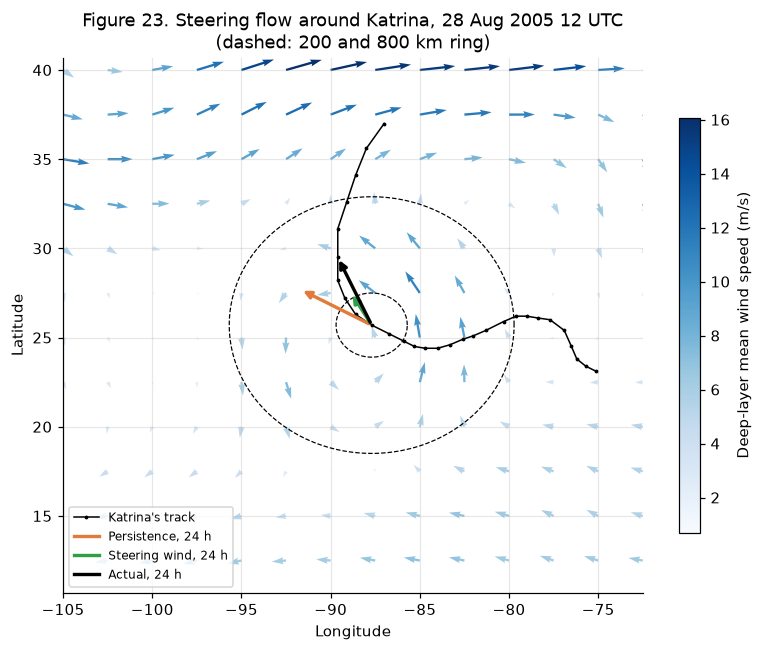

   persistence: 287 km error
 steering only: 232 km error


In [5]:
# To see what this means for one storm, we pick Hurricane Katrina at 12 UTC on 28 Aug 2005, shortly before landfall.
pick = S[S["SID"].isin(tracks.loc[tracks["NAME"].eq("KATRINA") & tracks["SEASON"].eq(2005)
                                  & tracks["BASIN"].eq("NA"), "SID"])
         & S["ISO_TIME"].eq(pd.Timestamp("2005-08-28 12:00"))].iloc[0]
# Here, we cut a 30 x 35 degree box of winds around the storm and average the three levels (the deep-layer mean).
with xr.open_dataset(NCEP_DIR / "ncep_winds_2005.nc") as ds:
    box = ds.sel(time=pick["ISO_TIME"], lat=slice(pick["LAT"] + 15, pick["LAT"] - 15),
                 lon=slice(pick["LON"] % 360 - 17.5, pick["LON"] % 360 + 17.5)).load()
dlm_u, dlm_v = box["uwnd"].mean("level"), box["vwnd"].mean("level")
glon = np.where(box["lon"].values > 180, box["lon"].values - 360, box["lon"].values)

# In the figure, arrows show the deep-layer wind, dashed circles the 200 and 800 km ring, and the colored
# arrows the 24-h motion predicted by persistence and by the steering wind, next to the actual motion.
fig, ax = plt.subplots(figsize=(8.5, 7))
q = ax.quiver(glon, box["lat"], dlm_u, dlm_v, np.hypot(dlm_u, dlm_v), cmap="Blues", scale=250, width=0.004)
fig.colorbar(q, ax=ax, shrink=0.7, label="Deep-layer mean wind speed (m/s)")
trk = tracks[tracks["SID"] == pick["SID"]]
ax.plot(trk["LON"], trk["LAT"], "k.-", lw=1, ms=3, label="Katrina's track")
th = np.linspace(0, 2 * np.pi, 200)
for r in RING_KM:
    ax.plot(pick["LON"] + r / (111.195 * np.cos(np.radians(pick["LAT"]))) * np.cos(th),
            pick["LAT"] + r / 111.195 * np.sin(th), "k--", lw=0.8)
to_deg = lambda dx, dy: (dx / (111.195 * np.cos(np.radians(pick["LAT"]))), dy / 111.195)
for (dx, dy), c, lab in [((4 * pick["dx_m0"], 4 * pick["dy_m0"]), "#E07B39", "Persistence, 24 h"),
                         ((pick["steer_dx"], pick["steer_dy"]), "#2F9E44", "Steering wind, 24 h"),
                         ((pick["dx_target"], pick["dy_target"]), "k", "Actual, 24 h")]:
    ddx, ddy = to_deg(dx, dy)
    ax.annotate("", xy=(pick["LON"] + ddx, pick["LAT"] + ddy), xytext=(pick["LON"], pick["LAT"]),
                arrowprops=dict(arrowstyle="-|>", color=c, lw=2.2))
    ax.plot([], [], color=c, lw=2.2, label=lab)
ax.set(xlim=(glon.min(), glon.max()), ylim=(pick["LAT"] - 15, pick["LAT"] + 15), aspect="equal",
       xlabel="Longitude", ylabel="Latitude",
       title="Figure 23. Steering flow around Katrina, 28 Aug 2005 12 UTC\n(dashed: 200 and 800 km ring)")
ax.legend(fontsize=8, loc="lower left")
savefig(fig, "fig23_steering_ring_katrina.png")
plt.show()
pick_df = S[S.index == pick.name]
for name, disp in {"persistence": 4 * pick_df[["dx_m0", "dy_m0"]].to_numpy(),
                   "steering only": pick_df[["steer_dx", "steer_dy"]].to_numpy()}.items():
    print(f"{name:>14s}: {track_error_km(pick_df, disp)[0]:.0f} km error")

Figure 23 makes the idea easy to see. Katrina had been heading west-northwest across the Gulf, and persistence simply extends that line, missing by **287 km**. In the ring, though, the flow had already turned. The ridge of high pressure to the east was steering winds northward along its western edge, and the westerlies were waiting further north. The steering wind alone pointed north-northwest and missed by **232 km**, much closer to the turn Katrina actually made toward Louisiana. Inside the inner circle the arrows swirl with Katrina's own winds, which is exactly why the ring starts 200 km out.

## 4. Exploring the new data

Before any model sees the winds, they deserve the same exploratory look the track data got in notebook 02.
Four questions guide it:

- **Coverage:** which seasons and basins have wind data, and how much is missing?
- **Balance:** do the Study B training, validation and test seasons see similar winds?
- **Relationships:** how do the wind features relate to each other, and to the part of the motion that
  persistence gets wrong?
- **Physics:** do the winds explain the recurvature found in the EDA, and how do storms move relative to them?

### Coverage

So, first, how much of the track record the winds cover. In the cell below, Figure 23b counts forecasts per
season, coloured by their Study B split, with grey for forecasts in seasons up to 2013 that have no wind file.
The table underneath breaks the Study B forecasts down by basin.

saved reports/figures/fig23b_wind_coverage.png


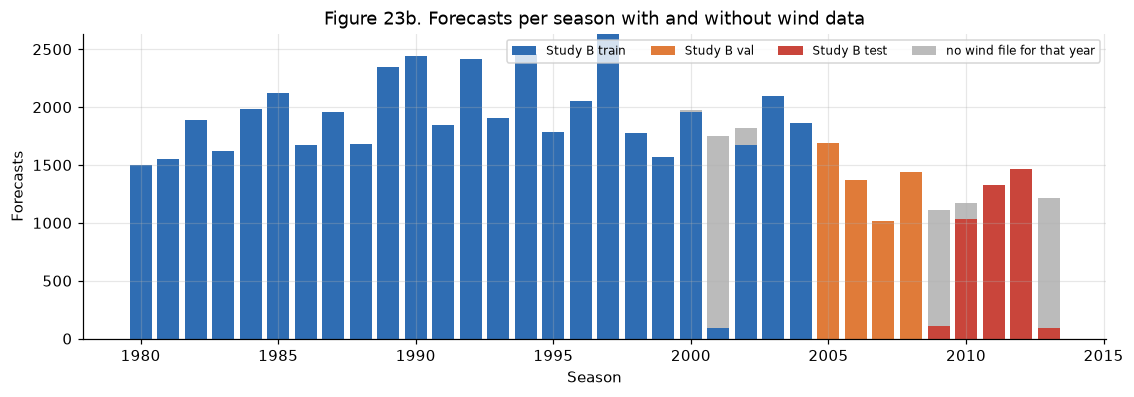

Forecasts in seasons 1980-2013 without wind data: 4,078 of 60,512 (6.7%)


split_b,train,val,test,share_pct
BASIN,,,,
EP,8497,892,485,17.5
NA,5766,1057,868,13.6
NI,1093,257,178,2.7
SA,5,0,0,0.0
SI,11291,1343,894,24.0
SP,5612,443,494,11.6
WP,14632,1522,1105,30.6


In [6]:
# First, coverage: within this cell we count forecasts per season, colored by Study B split, with grey for
# forecasts in seasons up to 2013 that fall in a year without a wind file.
upto2013 = S_all[S_all["SEASON"].le(2013)]
no_wind = upto2013[~upto2013["ISO_TIME"].dt.year.isin(years)].groupby("SEASON").size()
by_split = S.groupby(["SEASON", "split_b"]).size().unstack(fill_value=0).reindex(columns=["train", "val", "test"], fill_value=0)
seasons = range(1980, 2014)
fig, ax = plt.subplots(figsize=(12, 3.6))
bottom = np.zeros(len(seasons))
for split, c in (("train", "#2F6DB3"), ("val", "#E07B39"), ("test", "#C9453B")):
    vals = by_split[split].reindex(seasons, fill_value=0).to_numpy()
    ax.bar(list(seasons), vals, bottom=bottom, color=c, label=f"Study B {split}")
    bottom += vals
ax.bar(list(seasons), no_wind.reindex(seasons, fill_value=0).to_numpy(), bottom=bottom, color="#BBBBBB",
       label="no wind file for that year")
ax.set(xlabel="Season", ylabel="Forecasts", title="Figure 23b. Forecasts per season with and without wind data")
ax.legend(fontsize=8, ncol=4)
savefig(fig, "fig23b_wind_coverage.png")
plt.show()
print(f"Forecasts in seasons 1980-2013 without wind data: {no_wind.sum():,} of {len(upto2013):,} "
      f"({100 * no_wind.sum() / len(upto2013):.1f}%)")
# Then, to check the gaps don't tilt the data toward one ocean, we count forecasts per basin and split.
S.groupby(["BASIN", "split_b"]).size().unstack(fill_value=0)[["train", "val", "test"]].assign(
    share_pct=lambda d: (100 * d.sum(axis=1) / len(S)).round(1))

So, the winds cover the great majority of the record. Of the 60,512 forecasts in seasons up to 2013, only 4,078 (6.7%) fall in a year without a wind file, almost all of them in 2001, 2009 and 2013. A little grey also shows up in neighbouring seasons, because Southern Hemisphere seasons straddle New Year: part of the 2002 season, for example, happened in calendar year 2001.

Each basin keeps roughly its usual share: the western Pacific 30.6%, the south Indian Ocean 24.0%, the eastern Pacific 17.5% and the North Atlantic 13.6%, close to their shares in the full dataset (29.8%, 22.2%, 18.1% and 14.5%). In other words, the missing years thin the record slightly without tilting it toward any one ocean.

### Balance between the Study B splits

After all, a model trained on one set of winds and tested on another can only be trusted if the two look alike. So
next, Figure 23c compares the distributions of three summary winds across the Study B splits: the
deep-layer eastward wind, the deep-layer northward wind, and the strength of the vertical shear. The table
gives their means and spreads, along with the median distance from the equator.

saved reports/figures/fig23c_wind_by_split.png


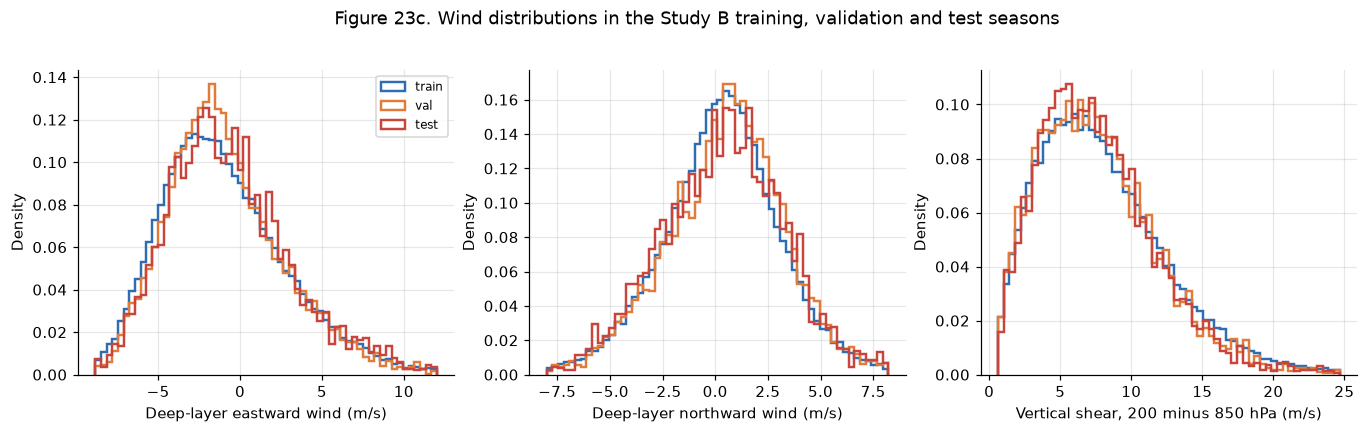

dlm_u       dlm_v       shear_speed       abs_lat
         mean   std  mean   std        mean   std  median
split_b                                                  
train   -0.95  3.97  0.30  2.86        8.04  4.67    16.6
val     -0.88  3.61  0.52  2.85        7.65  4.25    17.0
test    -0.60  3.79  0.40  3.00        7.67  4.28    17.7

In [7]:
# Next, balance: here we compare the wind distributions across the Study B splits as overlaid
# histograms, using the overall strength of the shear rather than its two components.
S["shear_speed"] = np.hypot(S["shear_u"], S["shear_v"])
cols3 = {"dlm_u": "Deep-layer eastward wind (m/s)", "dlm_v": "Deep-layer northward wind (m/s)",
         "shear_speed": "Vertical shear, 200 minus 850 hPa (m/s)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (col, label) in zip(axes, cols3.items()):
    lo, hi = np.percentile(S[col], [0.5, 99.5])
    for split, c in (("train", "#2F6DB3"), ("val", "#E07B39"), ("test", "#C9453B")):
        ax.hist(S.loc[S["split_b"] == split, col], bins=60, range=(lo, hi), density=True,
                histtype="step", lw=1.6, color=c, label=split)
    ax.set(xlabel=label, ylabel="Density")
axes[0].legend(fontsize=8)
fig.suptitle("Figure 23c. Wind distributions in the Study B training, validation and test seasons", y=1.03)
savefig(fig, "fig23c_wind_by_split.png")
plt.show()
# And the same comparison in numbers: means and spreads per split, plus median distance from the equator.
balance = S.groupby("split_b")[list(cols3)].agg(["mean", "std"]).round(2)
balance[("abs_lat", "median")] = S.groupby("split_b")["LAT"].apply(lambda x: x.abs().median()).round(1)
balance.reindex(["train", "val", "test"])

Here, the three Study B splits look very much alike. The deep-layer eastward wind averages −0.95, −0.88 and −0.60 m/s in training, validation and test, against a spread of about 4 m/s. The northward wind and the shear differ by similarly small amounts, and the test storms sit only about one degree further from the equator (median 17.7° against 16.6°). So the test seasons ask the models to work in familiar conditions, and any gain the winds bring can't be put down to a change in the weather between periods.

### How the wind features relate to each other and to the target

Here, the question is twofold. Between the features, strong correlations would mean redundancy, which
matters for how models use them. Between the features and the target, what counts is the link to the
**persistence error**, the part of the motion the models actually predict. Figure 23d shows the correlation
matrix over the Study B training forecasts, with the two components of persistence's error in the last two rows.

saved reports/figures/fig23d_wind_correlations.png


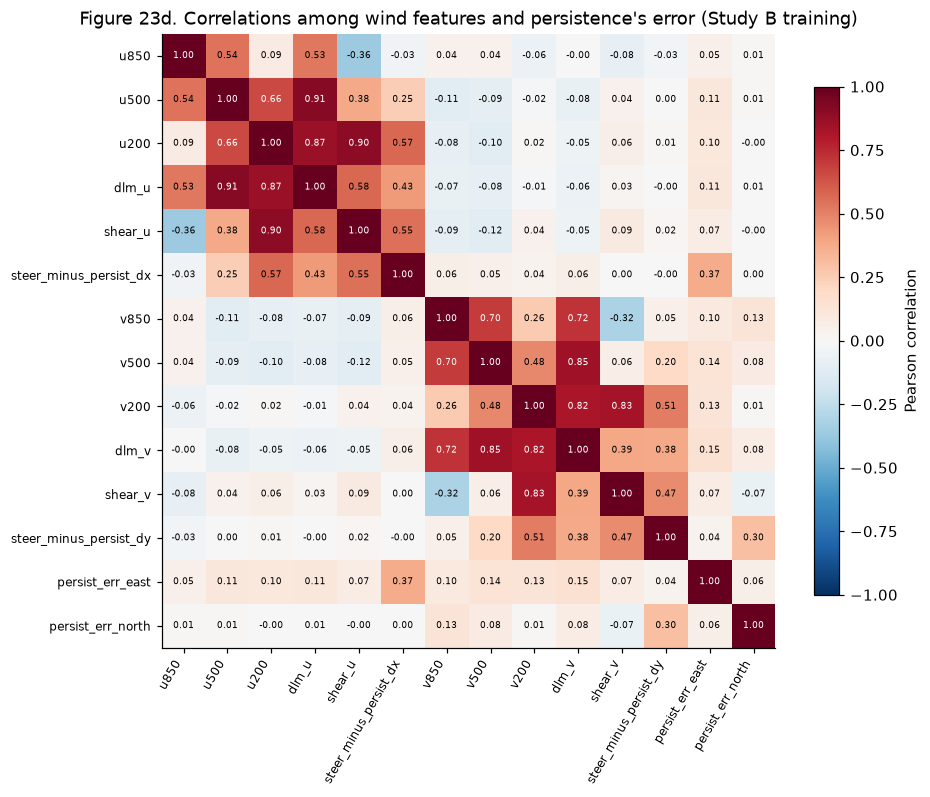

,"with persistence error, east","with persistence error, north"
u850,0.05,0.01
u500,0.11,0.01
u200,0.10,-0.00
dlm_u,0.11,0.01
shear_u,0.07,-0.00
steer_minus_persist_dx,0.37,0.00
v850,0.10,0.13
v500,0.14,0.08
v200,0.13,0.01
dlm_v,0.15,0.08


In [8]:
# Now the relationships. Using the Study B training forecasts only, we correlate the wind features
# with each other and with persistence's error, the part of the motion the models actually predict.
trn = S[S["split_b"] == "train"].copy()
trn["persist_err_east"] = trn["dx_target"] - 4 * trn["dx_m0"]
trn["persist_err_north"] = trn["dy_target"] - 4 * trn["dy_m0"]
corr_cols = ["u850", "u500", "u200", "dlm_u", "shear_u", "steer_minus_persist_dx",
             "v850", "v500", "v200", "dlm_v", "shear_v", "steer_minus_persist_dy",
             "persist_err_east", "persist_err_north"]
cm = trn[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(cm.iloc[i, j]) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Figure 23d. Correlations among wind features and persistence's error (Study B training)")
savefig(fig, "fig23d_wind_correlations.png")
plt.show()
# Here, we pull out the two columns that matter most: each feature's link to persistence's error.
pd.DataFrame({"with persistence error, east": cm.loc[corr_cols[:12], "persist_err_east"],
              "with persistence error, north": cm.loc[corr_cols[:12], "persist_err_north"]}).round(2)

Two clear patterns stand out.

- **Among the features, the winds at different heights overlap strongly.** The deep-layer eastward wind correlates at 0.91 with the 500 hPa wind and 0.87 with the 200 hPa wind, and the eastward shear is almost a copy of the upper-level wind (0.90). The eastward and northward components, by contrast, are nearly independent. That redundancy does no harm to regularized regression, trees or neural networks, but it means the 14 features carry fewer independent pieces of information than their number suggests.
- **Against the target, the raw winds say little.** None of them correlates with persistence's error by more than 0.15. What does correlate is the engineered disagreement between steering and persistence: 0.37 for the east–west error and 0.30 for the north–south error, each with its own component and almost nothing with the other.

In short, the wind on its own doesn't tell you where persistence goes wrong; the *comparison* between the wind and the storm's recent motion does. That's why those two features were built, and Section 10 shows XGBoost ranking them as its two most important inputs.

### The winds and recurvature

Back in notebook 02, storms turned from westward to eastward motion as they moved away from the equator.
If the steering idea is right, the winds should show the same turn, and storms should roughly follow them.
In the cell below, Figure 23e compares, in 5° latitude bands, the deep-layer wind with the storms' actual
24-hour motion, both in metres per second. The northward components are flipped in the southern hemisphere, so that
"poleward" means the same thing in both. The last table measures how storms move *relative* to the
steering flow, separately for each hemisphere.

saved reports/figures/fig23e_wind_by_latitude.png


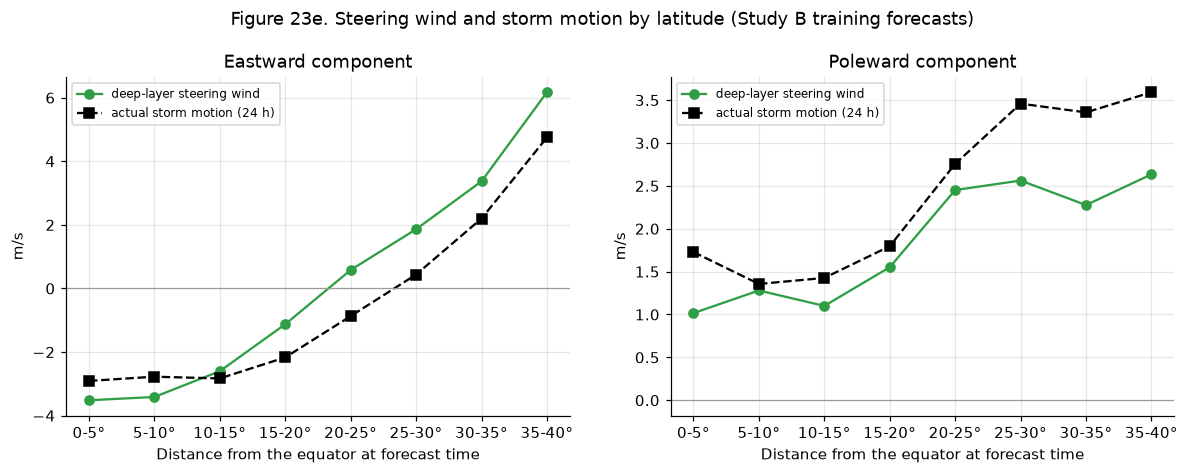

,forecasts,steering_east,motion_east,steering_poleward,motion_poleward,shear
band,,,,,,
0,128,-3.52,-2.91,1.02,1.73,7.50
5,3187,-3.41,-2.78,1.28,1.36,7.60
10,14090,-2.60,-2.83,1.10,1.43,7.24
15,16189,-1.13,-2.17,1.55,1.80,7.81
20,7233,0.58,-0.87,2.45,2.76,8.97
25,3446,1.86,0.44,2.56,3.46,9.63
30,1886,3.37,2.20,2.28,3.36,9.30
35,643,6.17,4.75,2.63,3.59,10.58


drift_east        drift_poleward       
                 mean median           mean median
hemisphere                                        
northern        -0.80  -0.81           0.62   0.65
southern        -0.75  -0.64          -0.11  -0.07

In [9]:
# So, do the winds explain recurvature? Within 5-degree latitude bands, we compare the mean steering wind
# with the storms' actual motion (both in m/s), flipping north-south in the south so 'poleward' matches.
trn["band"] = (trn["LAT"].abs() // 5 * 5).clip(upper=40).astype(int)
pole = np.sign(trn["LAT"])
trn["motion_east"] = trn["dx_target"] / KM_PER_24H
trn["motion_pole"] = pole * trn["dy_target"] / KM_PER_24H
trn["steer_pole"] = pole * trn["dlm_v"]
prof = trn.groupby("band").agg(forecasts=("LAT", "size"), steering_east=("dlm_u", "mean"),
                               motion_east=("motion_east", "mean"), steering_poleward=("steer_pole", "mean"),
                               motion_poleward=("motion_pole", "mean"), shear=("shear_speed", "mean"))
prof = prof[prof["forecasts"] >= 100]
labels = [f"{b}-{b + 5}°" if b < 40 else "40°+" for b in prof.index]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (s_col, m_col, title) in zip(axes, [("steering_east", "motion_east", "Eastward component"),
                                            ("steering_poleward", "motion_poleward", "Poleward component")]):
    ax.plot(labels, prof[s_col], "o-", color="#2F9E44", label="deep-layer steering wind")
    ax.plot(labels, prof[m_col], "s--", color="k", label="actual storm motion (24 h)")
    ax.axhline(0, color="#999", lw=0.8)
    ax.set(xlabel="Distance from the equator at forecast time", ylabel="m/s", title=title)
    ax.legend(fontsize=8)
fig.suptitle("Figure 23e. Steering wind and storm motion by latitude (Study B training forecasts)", y=1.03)
savefig(fig, "fig23e_wind_by_latitude.png")
plt.show()
display(prof.round(2))
# Finally, we measure how storms move relative to the steering flow in each hemisphere: the beta drift.
trn["hemisphere"] = np.where(trn["LAT"] >= 0, "northern", "southern")
trn["drift_east"] = trn["motion_east"] - trn["dlm_u"]
trn["drift_poleward"] = trn["motion_pole"] - trn["steer_pole"]
trn.groupby("hemisphere")[["drift_east", "drift_poleward"]].agg(["mean", "median"]).round(2)

So the winds explain the recurvature found in notebook 02. Near the equator the deep-layer flow blows from the east at about 3.4 m/s; it weakens with latitude, changes sign near 20°, and blows from the west at over 6 m/s beyond 35°. Storms follow the same curve, but with a steady offset. They move about **0.8 m/s further west** than the steering flow in both hemispheres, and in the northern hemisphere about **0.6 m/s further poleward**. That's the beta drift described by Holland (1983), measured here directly from the data (in the southern hemisphere the poleward part is close to zero in this sample). Shear also grows with latitude, from about 7 to over 10 m/s, as storms approach the jet stream.

Two practical consequences follow. A forecast that simply moves storms with the steering wind will be biased, which Section 6 confirms. And a learned model has to add the drift back, which it can do because the drift is so consistent.

## 5. Does the steering flow carry real signal?

Before training anything, a quick check that the features mean what they should. If storms really travel
with the steering flow, then the 24-hour steering displacement should line up with where storms actually
went. More importantly, the *disagreement* between steering and persistence should line up with persistence's
mistakes, because that's the part the models need to learn.

Figure 24 plots both relationships over the Study B training forecasts, as density maps since there are
tens of thousands of points.

saved reports/figures/fig24_steering_vs_motion.png


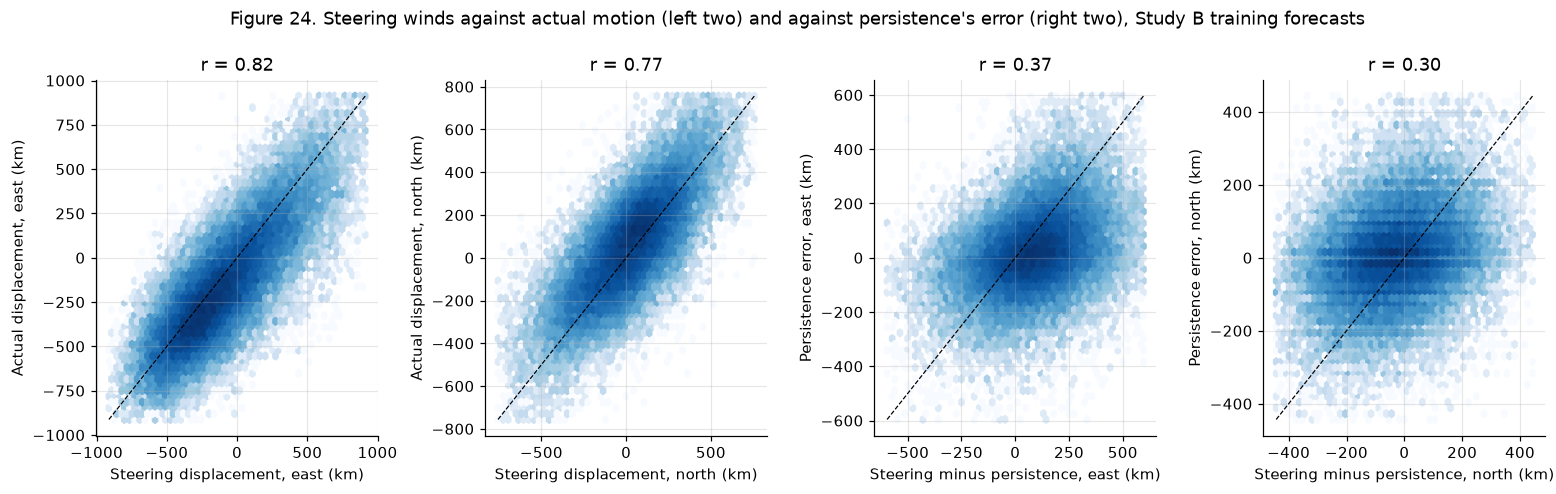

Persistence alone vs actual: r = 0.88 (east), 0.87 (north)


In [10]:
# Here, we check the signal directly: steering displacement against actual motion (left panels), and
# steering-minus-persistence against persistence's error (right panels), as density maps.
tr = S[S["split_b"] == "train"]
resid_x, resid_y = tr["dx_target"] - 4 * tr["dx_m0"], tr["dy_target"] - 4 * tr["dy_m0"]
panels = [(tr["steer_dx"], tr["dx_target"], "Steering displacement, east (km)", "Actual displacement, east (km)"),
          (tr["steer_dy"], tr["dy_target"], "Steering displacement, north (km)", "Actual displacement, north (km)"),
          (tr["steer_minus_persist_dx"], resid_x, "Steering minus persistence, east (km)", "Persistence error, east (km)"),
          (tr["steer_minus_persist_dy"], resid_y, "Steering minus persistence, north (km)", "Persistence error, north (km)")]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw={"wspace": 0.38})
corr = {}
for ax, (x, y, xl, yl) in zip(axes, panels):
    lim = np.percentile(np.abs(np.r_[x, y]), 99)
    ax.hexbin(x, y, gridsize=50, extent=(-lim, lim, -lim, lim), bins="log", cmap="Blues", mincnt=1)
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
    r = np.corrcoef(x, y)[0, 1]
    corr[xl] = r
    ax.set(xlabel=xl, ylabel=yl, title=f"r = {r:.2f}")
fig.suptitle("Figure 24. Steering winds against actual motion (left two) and against persistence's error (right two), "
             "Study B training forecasts", y=1.03)
savefig(fig, "fig24_steering_vs_motion.png")
plt.show()
print("Persistence alone vs actual: r =", np.corrcoef(4 * tr["dx_m0"], tr["dx_target"])[0, 1].round(2), "(east),",
      np.corrcoef(4 * tr["dy_m0"], tr["dy_target"])[0, 1].round(2), "(north)")

So the features do carry real signal, but not in the way one might first expect. On its own, the steering displacement lines up with actual motion **less** closely than persistence does (r = 0.82 and 0.77, compared with 0.88 and 0.87). The right-hand panels are the important ones, though. The disagreement between steering and persistence correlates with persistence's own error (r = 0.37 east, 0.30 north). In other words, when the winds point somewhere other than the storm's recent heading, the storm really does tend to bend that way. That's information the track-only models never had. (The horizontal banding in the last panel comes from best-track positions being rounded to 0.1°.)

## 6. Simple forecasts on the Study B split

With a new split, the reference points need recomputing. The helper below scores any forecast on the Study B
validation or test seasons, in the same way as every earlier notebook. Then we score two forecasts that need
no training:

- **Persistence**, the straight-line extrapolation.
- **Steering only**, which moves the storm with the deep-layer wind and nothing else. It's crude (no beta
  drift, no storm history), but it shows how much the wind alone knows.

In [11]:
va = S[S["split_b"] == "val"].reset_index(drop=True)
te = S[S["split_b"] == "test"].reset_index(drop=True)
tr = S[S["split_b"] == "train"].reset_index(drop=True)
errors = {"val": {}, "test": {}}

def score(name, pred_val, pred_test):
    for part, data, pred in (("val", va, pred_val), ("test", te, pred_test)):
        errors[part][name] = track_error_km(data, pred)

def table(part):
    data = va if part == "val" else te
    na, hi = data["BASIN"].eq("NA").to_numpy(), data["LAT"].abs().ge(25).to_numpy()
    t = pd.DataFrame({m: {"mean_km": e.mean(), "median_km": np.median(e), "p90_km": np.percentile(e, 90),
                          "NA_mean_km": e[na].mean(), "beyond_25deg_km": e[hi].mean()}
                      for m, e in errors[part].items()}).T
    t["skill_vs_persistence_%"] = 100 * (1 - t["mean_km"] / t.loc["Persistence", "mean_km"])
    return t.round(1)

steer = lambda d: d[["steer_dx", "steer_dy"]].to_numpy()
score("Persistence", persistence_displacement(va), persistence_displacement(te))
score("Steering only", steer(va), steer(te))
table("val")

,mean_km,median_km,p90_km,NA_mean_km,beyond_25deg_km,skill_vs_persistence_%
Persistence,159.4,137.4,294.1,177.2,208.6,0.0
Steering only,218.1,193.1,387.7,241.8,236.8,-36.8


On the Study B validation seasons, persistence errs by **159 km**. Moving the storm with the steering wind alone is far worse, at 218 km. That's no surprise after the last two checks: storms drift relative to the flow, the 2.5° grid is coarse, and a single ring average is a crude summary. So the winds aren't a forecast on their own. Their value, if any, has to come from combining them with the storm's track, which is what the next two models do.

## 7. Linear regression with and without winds

Next, the first real test. We fit the CLIPER-style ridge regression from notebook 03 twice on the Study B
training seasons: once with the original 22 track features, and once with the 14 steering features added.
Both predict the correction to persistence, and both use the same penalty strength chosen in notebook 03.
A linear model is a useful first check, because if the winds help even here, the gain doesn't depend on
some quirk of a complicated model.

In [12]:
BASINS = sorted(S_all["BASIN"].unique())
for b in BASINS:
    for d in (tr, va, te):
        d[f"basin_{b}"] = (d["BASIN"] == b).astype(float)
X_TRACK = FEATURE_COLS + [f"basin_{b}" for b in BASINS]
assert X_TRACK == XGB_CFG["features"]
X_WIND = X_TRACK + STEERING_COLS
FEATURE_SETS = {"tracks only": X_TRACK, "tracks + winds": X_WIND}

P_tr, P_va, P_te = (persistence_displacement(d) for d in (tr, va, te))
R_tr, R_va = tr[TARGET_COLS].to_numpy() - P_tr, va[TARGET_COLS].to_numpy() - P_va

for label, cols in FEATURE_SETS.items():
    m = make_pipeline(StandardScaler(), Ridge(alpha=XGB_CFG["ridge_alpha"])).fit(tr[cols].to_numpy(), R_tr)
    score(f"Ridge, {label}", m.predict(va[cols].to_numpy()) + P_va, m.predict(te[cols].to_numpy()) + P_te)
table("val")

,mean_km,median_km,p90_km,NA_mean_km,beyond_25deg_km,skill_vs_persistence_%
Persistence,159.4,137.4,294.1,177.2,208.6,0.0
Steering only,218.1,193.1,387.7,241.8,236.8,-36.8
"Ridge, tracks only",151.5,132.1,272.0,165.2,182.4,4.9
"Ridge, tracks + winds",140.8,124.8,252.8,146.8,163.6,11.7


Here, the gain is immediate. With the same linear model and the same penalty, adding the winds cuts validation error from **151.5 to 140.8 km**, a drop of almost 11 km. To put that in perspective, a *linear* model with winds now matches the track-only XGBoost (141.0 km) from the next section. Its North Atlantic error falls even further, from 165 to 147 km.

## 8. XGBoost with and without winds

Now the stronger model. We train XGBoost with exactly the settings chosen in notebook 03 (residual target,
trees 6 levels deep, learning rate 0.05), again once per feature set. Early stopping watches the Study B
validation seasons, so the test seasons play no part in training at all. Each fit takes about a minute.

In [13]:
def fit_xgb(X_train, Y_train, X_val, Y_val):
    models = []
    for j in range(Y_train.shape[1]):
        m = xgb.XGBRegressor(n_estimators=3000, learning_rate=XGB_CFG["learning_rate"], max_depth=XGB_CFG["max_depth"],
                             subsample=0.8, colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                             early_stopping_rounds=100, n_jobs=N_THREADS, random_state=SEED)
        m.fit(X_train, Y_train[:, j], eval_set=[(X_val, Y_val[:, j])], verbose=False)
        models.append(m)
    return models

predict_xgb = lambda models, X: np.column_stack([m.predict(X) for m in models])
xgb_models, fit_log = {}, []
for label, cols in FEATURE_SETS.items():
    t0 = time.time()
    models = fit_xgb(tr[cols].to_numpy(), R_tr, va[cols].to_numpy(), R_va)
    xgb_models[label] = models
    score(f"XGBoost, {label}", predict_xgb(models, va[cols].to_numpy()) + P_va,
          predict_xgb(models, te[cols].to_numpy()) + P_te)
    fit_log.append({"features": label, "n_features": len(cols), "trees": [m.best_iteration + 1 for m in models],
                    "secs": round(time.time() - t0)})
print(pd.DataFrame(fit_log).to_string(index=False))
table("val")

      features  n_features      trees  secs
   tracks only          22 [303, 229]     1
tracks + winds          36 [571, 282]     2


,mean_km,median_km,p90_km,NA_mean_km,beyond_25deg_km,skill_vs_persistence_%
Persistence,159.4,137.4,294.1,177.2,208.6,0.0
Steering only,218.1,193.1,387.7,241.8,236.8,-36.8
"Ridge, tracks only",151.5,132.1,272.0,165.2,182.4,4.9
"Ridge, tracks + winds",140.8,124.8,252.8,146.8,163.6,11.7
"XGBoost, tracks only",141.0,121.4,255.8,156.9,170.3,11.5
"XGBoost, tracks + winds",129.9,114.4,233.8,140.7,155.9,18.5


XGBoost gains just as much: **141.0 → 129.9 km** on validation, and 156.9 → 140.7 km in the North Atlantic. The biggest improvement comes beyond 25° latitude (170 → 156 km), where storms recurve and persistence struggles most. Notice also that early stopping let the wind-aware model grow about twice as many trees for the east–west component (571 against 303), a sign it found more structure worth learning. Both fits take only seconds, so the extra features cost almost nothing to use.

## 9. The verdict on the test seasons

Every choice so far was made on the validation seasons. Now, finally, the Study B **test** seasons, which no
model has seen in any form. The table below gives the same summary on those seasons, and the paired
bootstrap over storms (from notebook 03) checks whether each with/without-winds gap could be chance.
A positive difference means adding the winds helped.

In [14]:
def paired_bootstrap(err_a, err_b, groups, n_boot=2000, seed=SEED):
    diff = pd.DataFrame({"g": groups, "d": err_a - err_b}).groupby("g")["d"].agg(["sum", "size"])
    s, n = diff["sum"].to_numpy(), diff["size"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    boots = s[idx].sum(axis=1) / n[idx].sum(axis=1)
    return s.sum() / n.sum(), *np.percentile(boots, [2.5, 97.5])

rows = []
for part, data in (("val", va), ("test", te)):
    for model in ("Ridge", "XGBoost"):
        a, b = errors[part][f"{model}, tracks only"], errors[part][f"{model}, tracks + winds"]
        est, lo, hi = paired_bootstrap(a, b, data["SID"])
        rows.append({"seasons": part, "model": model, "without_km": a.mean(), "with_km": b.mean(),
                     "gain_km": est, "ci_low_km": lo, "ci_high_km": hi, "gain_%": 100 * est / a.mean()})
gains = pd.DataFrame(rows).set_index(["seasons", "model"]).round(1)
display(table("test"))
gains

,mean_km,median_km,p90_km,NA_mean_km,beyond_25deg_km,skill_vs_persistence_%
Persistence,171.6,144.9,329.8,182.9,232.9,0.0
Steering only,225.2,200.3,399.3,247.1,272.9,-31.2
"Ridge, tracks only",161.8,136.6,307.9,162.5,207.6,5.7
"Ridge, tracks + winds",147.1,127.4,274.3,145.1,187.7,14.3
"XGBoost, tracks only",152.1,131.9,286.4,153.4,187.2,11.4
"XGBoost, tracks + winds",138.1,119.7,257.0,139.6,173.7,19.5


without_km  with_km  gain_km  ci_low_km  ci_high_km  gain_%
seasons model                                                               
val     Ridge         151.5    140.8     10.7        8.6        13.0     7.1
        XGBoost       141.0    129.9     11.1        9.0        13.3     7.9
test    Ridge         161.8    147.1     14.8       12.2        17.6     9.1
        XGBoost       152.1    138.1     14.0       11.2        17.0     9.2

And the test seasons confirm it. On 4,024 forecasts that no model had seen, adding the winds improves XGBoost from **152.1 to 138.1 km**, a gain of **14.0 km** (95% interval 11.2 to 17.0 km), or 9.2%. The linear model gains 14.8 km. Both intervals sit far from zero, so this is clearly not luck. Skill over persistence rises from 11.4% to 19.5%, and North Atlantic error drops from 153 to 140 km.

That said, errors are higher on test than on validation for every model, persistence included, so the 2009–2013 storms were simply harder to forecast. The *relative* gain from the winds held up, and even grew. For scale, two full rounds of tuning in the main study improved the GRU by about 1.5 km. A second data source was worth roughly ten times that.

Figure 25 brings the main numbers together: mean error for each forecast on the validation and test seasons.

saved reports/figures/fig25_studyb_xgb_results.png


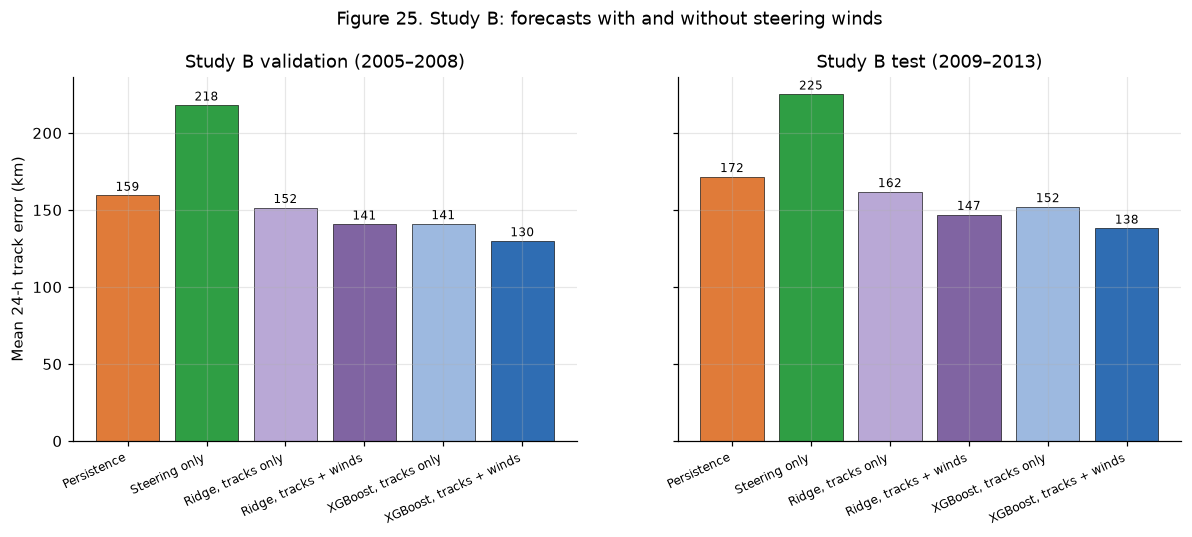

In [15]:
order = ["Persistence", "Steering only", "Ridge, tracks only", "Ridge, tracks + winds",
         "XGBoost, tracks only", "XGBoost, tracks + winds"]
colors = ["#E07B39", "#2F9E44", "#B9A8D6", "#8064A2", "#9DB9E0", "#2F6DB3"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, part in zip(axes, ("val", "test")):
    vals = [errors[part][m].mean() for m in order]
    ax.bar(range(len(order)), vals, color=colors, edgecolor="k", lw=0.4)
    for i, v in enumerate(vals):
        ax.text(i, v + 3, f"{v:.0f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(order)), order, fontsize=8, rotation=25, ha="right")
    ax.set_title(f"Study B {'validation (2005–2008)' if part == 'val' else 'test (2009–2013)'}")
axes[0].set_ylabel("Mean 24-h track error (km)")
fig.suptitle("Figure 25. Study B: forecasts with and without steering winds", y=1.02)
savefig(fig, "fig25_studyb_xgb_results.png")
plt.show()

## 10. What does XGBoost do with the winds?

Last, let's open up the wind-aware XGBoost and see how much it leans on the new features. As in notebook 03,
Figure 26 shows each feature's share of total gain, averaged over the east–west and north–south models, with
the steering features in green.

saved reports/figures/fig26_xgb_importance_with_winds.png


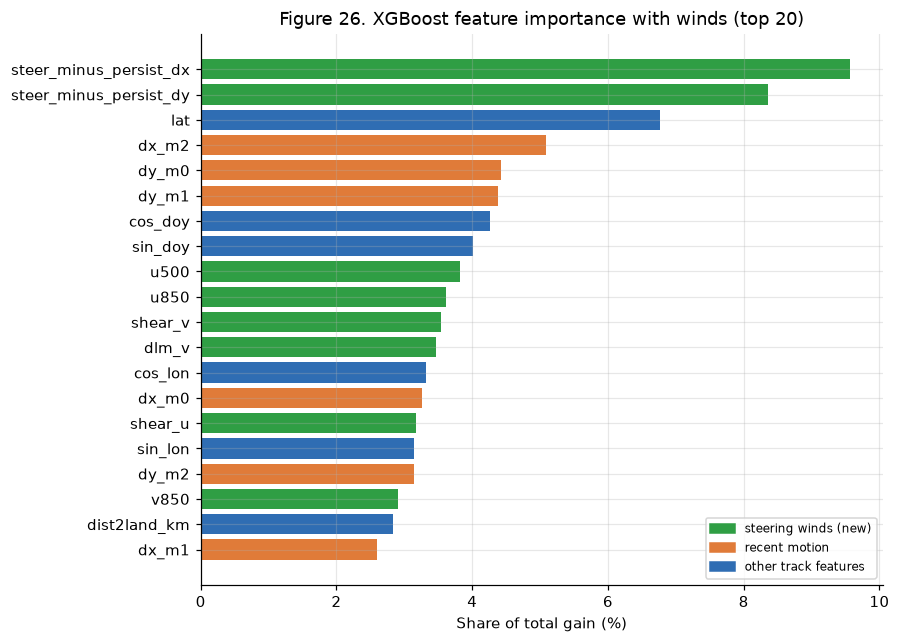

Steering features together: 47.4% of total gain; recent motion: 22.9%


steer_minus_persist_dx    9.6
steer_minus_persist_dy    8.4
lat                       6.8
dx_m2                     5.1
dy_m0                     4.4
dy_m1                     4.4
cos_doy                   4.3
sin_doy                   4.0
dtype: float64

In [16]:
cols = FEATURE_SETS["tracks + winds"]
gain = pd.DataFrame({j: pd.Series(m.get_booster().get_score(importance_type="total_gain"))
                     for j, m in enumerate(xgb_models["tracks + winds"])}).fillna(0)
gain.index = [cols[int(f[1:])] if f.startswith("f") and f[1:].isdigit() else f for f in gain.index]
gain = (gain / gain.sum()).mean(axis=1).sort_values()
top = gain.tail(20)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values * 100,
        color=["#2F9E44" if c in STEERING_COLS else "#E07B39" if c in MOTION_COLS else "#2F6DB3" for c in top.index])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2F9E44", label="steering winds (new)"), Patch(color="#E07B39", label="recent motion"),
                   Patch(color="#2F6DB3", label="other track features")], fontsize=8, loc="lower right")
ax.set(xlabel="Share of total gain (%)", title="Figure 26. XGBoost feature importance with winds (top 20)")
savefig(fig, "fig26_xgb_importance_with_winds.png")
plt.show()
print(f"Steering features together: {gain[STEERING_COLS].sum() * 100:.1f}% of total gain; "
      f"recent motion: {gain[MOTION_COLS].sum() * 100:.1f}%")
(gain.sort_values(ascending=False) * 100).round(1).head(8)

So the model does lean heavily on the new data. Steering features account for **47%** of total gain, against 23% for recent motion. The top two features of all are `steer_minus_persist_dx` and `steer_minus_persist_dy`, the disagreement features engineered in Section 3. In effect, the trees learned the rule "trust persistence, unless the steering flow says the storm is about to turn". Latitude comes next, which fits too: where a storm sits largely decides which wind regime it's in.

## 11. Saving for notebook 07b

Finally, we save what notebook 07b needs. The steering features go into one table keyed by segment and time,
along with each forecast's Study B split, so the GRU can use exactly the same forecasts and features. The
per-forecast errors of every model here are saved too, so 07b can line them up with the GRU, forecast by
forecast, without loading XGBoost.

In [17]:
keep = ["SID", "SEG_ID", "BASIN", "SEASON", "ISO_TIME", "split_b"]
S[keep + STEERING_COLS].to_csv(PROCESSED / "steering_features.csv.gz", index=False)

pred_out = pd.concat([d[keep] for d in (va, te)], ignore_index=True)
for m in order:
    pred_out[f"err_{m.lower().replace(', ', '_').replace(' + ', '_').replace(' ', '_')}_km"] = \
        np.r_[errors["val"][m], errors["test"][m]]
pred_out.to_csv(PROCESSED / "preds_studyb_xgb.csv", index=False)
print("saved data/processed/steering_features.csv.gz, data/processed/preds_studyb_xgb.csv")
print("columns:", [c for c in pred_out.columns if c.startswith("err_")])

saved data/processed/steering_features.csv.gz, data/processed/preds_studyb_xgb.csv
columns: ['err_persistence_km', 'err_steering_only_km', 'err_ridge_tracks_only_km', 'err_ridge_tracks_winds_km', 'err_xgboost_tracks_only_km', 'err_xgboost_tracks_winds_km']


## Summary

- **A second dataset.** NCEP/NCAR Reanalysis 1 winds at 850, 500 and 200 hPa, every 6 hours, for 31 years (1980–2012, minus 2001 and 2009). That's 56,434 forecasts, split chronologically into 1980–2004 for training, 2005–2008 for validation and 2009–2013 for testing.
- **What the EDA showed.** The winds cover 93% of forecasts up to 2013 with no basin skew, and the Study B splits see near-identical winds. Winds at different heights are strongly correlated with each other but only weakly with persistence's error, unlike the engineered steering-minus-persistence features (r = 0.37 and 0.30). Storms drift about 0.8 m/s west of the steering flow (beta drift), and the flow itself turns from easterly to westerly near 20° latitude, which is what drives recurvature.
- **The features.** Ring-averaged steering winds (200–800 km) at the forecast time only, plus the deep-layer mean, shear and the steering-versus-persistence disagreement. Only information available when the forecast is issued is used.
- **On their own, the winds are a poor forecast** (218 km against persistence's 159 km), but they clearly know where persistence goes wrong (r ≈ 0.3–0.4).
- **Combined with the track, they help a lot.** On the test seasons, XGBoost improves by 14.0 km (152.1 → 138.1 km, 95% CI 11.2–17.0), and linear regression by 14.8 km. That's roughly ten times what hyperparameter tuning achieved.
- **The gains are biggest where they matter most:** at higher latitudes, where storms recurve, and in the North Atlantic.

Next, notebook 07b asks the same question of the GRU: does a recurrent network make better use of the winds than the trees do?

## References

Chan, J. C. L. (2005). The physics of tropical cyclone motion. *Annual Review of Fluid Mechanics, 37*,
99–128. https://doi.org/10.1146/annurev.fluid.37.061903.175702

Chan, J. C. L., & Gray, W. M. (1982). Tropical cyclone movement and surrounding flow relationships.
*Monthly Weather Review, 110*(10), 1354–1374.
https://doi.org/10.1175/1520-0493(1982)110<1354:TCMASF>2.0.CO;2

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM
SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794).
https://doi.org/10.1145/2939672.2939785

Gahtan, J., Knapp, K. R., Schreck, C. J., Diamond, H. J., Kossin, J. P., & Kruk, M. C. (2024).
*International Best Track Archive for Climate Stewardship (IBTrACS) Project, Version 4r01*. NOAA National
Centers for Environmental Information. https://doi.org/10.25921/82ty-9e16

Kalnay, E., Kanamitsu, M., Kistler, R., Collins, W., Deaven, D., Gandin, L., ... Joseph, D. (1996). The
NCEP/NCAR 40-year reanalysis project. *Bulletin of the American Meteorological Society, 77*(3), 437–471.
https://doi.org/10.1175/1520-0477(1996)077<0437:TNYRP>2.0.CO;2

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author
reviewed each step, ran the notebook, and checked the outputs.*